# UC: Aprendizagem Profunda - Trabalho Prático
## Tarefa 3: Modelos de Deep Learning em PyTorch

**Docentes:** Miguel Rocha, Lázaro Makili  
**Objetivo:** Desenvolver e comparar modelos de Deep Learning em **PyTorch** capazes de distinguir entre texto gerado por Inteligência Artificial (classe `1`) e texto escrito por Humanos (classe `0`).

### Modelos Desenvolvidos:
1. **Tabular Deep Neural Network (DNN)** com representação TF-IDF (1000 termos);
2. **Recurrent Neural Network Bidirecional (BiLSTM)** com camada de *Embeddings* treinada de raiz;
3. **Transformer Encoder** com Codificação Posicional Sinusoidal e *Multi-Head Self-Attention* nativo em PyTorch.

--- 
### 1. Configuração de Ambiente, Dependências e Reprodutibilidade

In [25]:
import os
import math
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

# Configurar estilo gráfico
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (9, 5)

# Garantir reprodutibilidade
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"[*] Dispositivo de execução: {device}")

# Criar pasta para persistência dos modelos
os.makedirs("../models", exist_ok=True)
os.makedirs("models", exist_ok=True)

[*] Dispositivo de execução: cpu


--- 
### 2. Carregamento e Preparação dos Dados (Limpos da Tarefa 1)

In [26]:
# Caminhos para os ficheiros limpos gerados na Tarefa 1
path_train = os.path.join("..", "data", "train_clean.csv")
path_val = os.path.join("..", "data", "val_clean.csv")
path_test = os.path.join("..", "data", "test_clean.csv")

# Fallback caso o notebook seja executado na raiz do projeto
if not os.path.exists(path_train):
    path_train = os.path.join("data", "train_clean.csv")
    path_val = os.path.join("data", "val_clean.csv")
    path_test = os.path.join("data", "test_clean.csv")

df_train = pd.read_csv(path_train)
df_val = pd.read_csv(path_val)
df_test = pd.read_csv(path_test)

train_texts = df_train['text'].astype(str).tolist()
train_labels = df_train['label_num'].values.astype(np.float32)

val_texts = df_val['text'].astype(str).tolist()
val_labels = df_val['label_num'].values.astype(np.float32)

test_texts = df_test['text'].astype(str).tolist()
test_labels = df_test['label_num'].values.astype(np.float32)

print(f"Divisão dos Dados:")
print(f" - Treino:     {len(train_texts)} amostras (Humanos: {int(np.sum(train_labels==0))}, IA: {int(np.sum(train_labels==1))})")
print(f" - Validação:  {len(val_texts)} amostras")
print(f" - Teste:      {len(test_texts)} amostras")

Divisão dos Dados:
 - Treino:     104 amostras (Humanos: 53, IA: 51)
 - Validação:  13 amostras
 - Teste:      13 amostras


--- 
### 3. Pipeline e Motor Genérico de Treino e Avaliação

Implementamos uma rotina genérica `train_and_evaluate` que suporta:
- Mini-batch gradient descent com `DataLoader`;
- Monitorização de perda (`Binary Cross Entropy with Logits`);
- Paragem Precoce (*Early Stopping*);
- Salvamento automático do melhor *checkpoint* (`.pt`);
- Visualização gráfica das curvas de perda e exatidão.

In [27]:
def train_and_evaluate(
    model, train_loader, val_loader, test_loader,
    optimizer, criterion, epochs=40, patience=8,
    model_save_path="models/best_model.pt", model_name="Modelo"
):
    model = model.to(device)
    best_val_loss = float('inf')
    patience_counter = 0
    
    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    
    for epoch in range(1, epochs + 1):
        # --- Treino ---
        model.train()
        t_loss, t_correct, t_total = 0.0, 0, 0
        for X_b, y_b in train_loader:
            X_b, y_b = X_b.to(device), y_b.to(device)
            optimizer.zero_grad()
            logits = model(X_b)
            loss = criterion(logits, y_b)
            loss.backward()
            optimizer.step()
            
            t_loss += loss.item() * len(y_b)
            preds = (torch.sigmoid(logits) >= 0.5).float()
            t_correct += (preds == y_b).sum().item()
            t_total += len(y_b)
            
        train_loss = t_loss / t_total
        train_acc = t_correct / t_total
        
        # --- Validação ---
        model.eval()
        v_loss, v_correct, v_total = 0.0, 0, 0
        with torch.no_grad():
            for X_b, y_b in val_loader:
                X_b, y_b = X_b.to(device), y_b.to(device)
                logits = model(X_b)
                loss = criterion(logits, y_b)
                
                v_loss += loss.item() * len(y_b)
                preds = (torch.sigmoid(logits) >= 0.5).float()
                v_correct += (preds == y_b).sum().item()
                v_total += len(y_b)
                
        val_loss = v_loss / v_total
        val_acc = v_correct / v_total
        
        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['train_acc'].append(train_acc)
        history['val_acc'].append(val_acc)
        
        # Checkpoint & Early Stopping
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            patience_counter = 0
            torch.save(model.state_dict(), model_save_path)
        else:
            patience_counter += 1
            if patience_counter >= patience:
                print(f"[*] Paragem precoce na época {epoch}! (Melhor Val Loss: {best_val_loss:.4f})")
                break

    # --- Avaliação no Teste ---
    model.load_state_dict(torch.load(model_save_path, map_location=device))
    model.eval()
    all_preds, all_targets = [], []
    with torch.no_grad():
        for X_b, y_b in test_loader:
            X_b = X_b.to(device)
            logits = model(X_b)
            preds = (torch.sigmoid(logits) >= 0.5).float().cpu().numpy()
            all_preds.extend(preds.flatten())
            all_targets.extend(y_b.flatten().numpy())
            
    all_preds = np.array(all_preds)
    all_targets = np.array(all_targets)
    
    acc = accuracy_score(all_targets, all_preds)
    prec = precision_score(all_targets, all_preds, zero_division=0)
    rec = recall_score(all_targets, all_preds, zero_division=0)
    f1 = f1_score(all_targets, all_preds, zero_division=0)
    cm = confusion_matrix(all_targets, all_preds)
    
    # Plot de Curvas de Treino
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))
    ax1.plot(history['train_loss'], label='Treino Loss', color='royalblue')
    ax1.plot(history['val_loss'], label='Validação Loss', color='crimson', linestyle='--')
    ax1.set_title(f'{model_name} - Função de Perda (Loss)')
    ax1.set_xlabel('Época')
    ax1.set_ylabel('Loss')
    ax1.legend()
    
    ax2.plot(history['train_acc'], label='Treino Acc', color='royalblue')
    ax2.plot(history['val_acc'], label='Validação Acc', color='crimson', linestyle='--')
    ax2.set_title(f'{model_name} - Exatidão (Accuracy)')
    ax2.set_xlabel('Época')
    ax2.set_ylabel('Accuracy')
    ax2.legend()
    plt.show()
    
    # Heatmap da Matriz de Confusão
    plt.figure(figsize=(4, 3))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['Humano', 'IA'], yticklabels=['Humano', 'IA'])
    plt.title(f'Matriz de Confusão ({model_name})')
    plt.xlabel('Previsão')
    plt.ylabel('Real')
    plt.show()
    
    return {
        'Model': model_name,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1,
        'Checkpoint': model_save_path
    }

--- 
### 4. Modelo 1: Tabular Deep Neural Network (DNN com TF-IDF)

[*] Paragem precoce na época 9! (Melhor Val Loss: 0.6947)


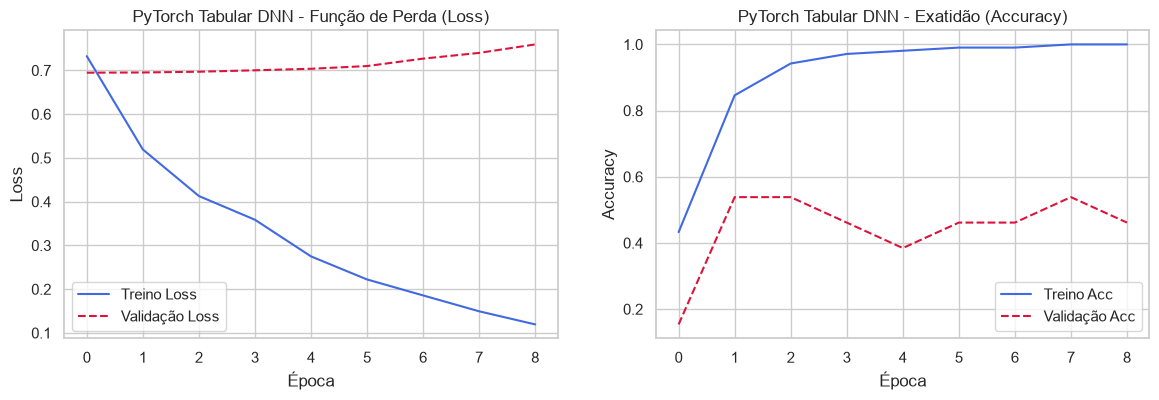

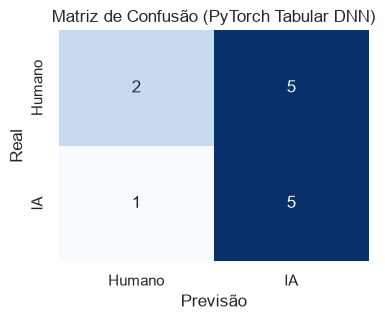

In [28]:
# 1. Extração de Features TF-IDF
vectorizer = TfidfVectorizer(max_features=1000, stop_words='english')
X_train_tfidf = vectorizer.fit_transform(train_texts).toarray()
X_val_tfidf = vectorizer.transform(val_texts).toarray()
X_test_tfidf = vectorizer.transform(test_texts).toarray()

class TabularDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32).unsqueeze(1)
    def __len__(self):
        return len(self.X)
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

train_tab_loader = DataLoader(TabularDataset(X_train_tfidf, train_labels), batch_size=16, shuffle=True)
val_tab_loader = DataLoader(TabularDataset(X_val_tfidf, val_labels), batch_size=16, shuffle=False)
test_tab_loader = DataLoader(TabularDataset(X_test_tfidf, test_labels), batch_size=16, shuffle=False)

# 2. Arquitetura DNN
class TabularDNN(nn.Module):
    def __init__(self, input_dim=1000, hidden1=128, hidden2=64, dropout_rate=0.3):
        super(TabularDNN, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, hidden1),
            nn.BatchNorm1d(hidden1),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            
            nn.Linear(hidden1, hidden2),
            nn.BatchNorm1d(hidden2),
            nn.ReLU(),
            nn.Dropout(dropout_rate * 0.7),
            
            nn.Linear(hidden2, 1)
        )
    def forward(self, x):
        return self.network(x)

model_dnn = TabularDNN(input_dim=1000)
opt_dnn = optim.AdamW(model_dnn.parameters(), lr=0.001, weight_decay=1e-4)
criterion = nn.BCEWithLogitsLoss()

res_dnn = train_and_evaluate(
    model_dnn, train_tab_loader, val_tab_loader, test_tab_loader,
    opt_dnn, criterion, epochs=40, patience=8,
    model_save_path="models/best_pytorch_dnn.pt", model_name="PyTorch Tabular DNN"
)

--- 
### 5. Modelo 2: BiLSTM com Camada de Embeddings Treinada de Raiz

Vocabulário construído com 3871 tokens únicos.
[*] Paragem precoce na época 18! (Melhor Val Loss: 0.4646)


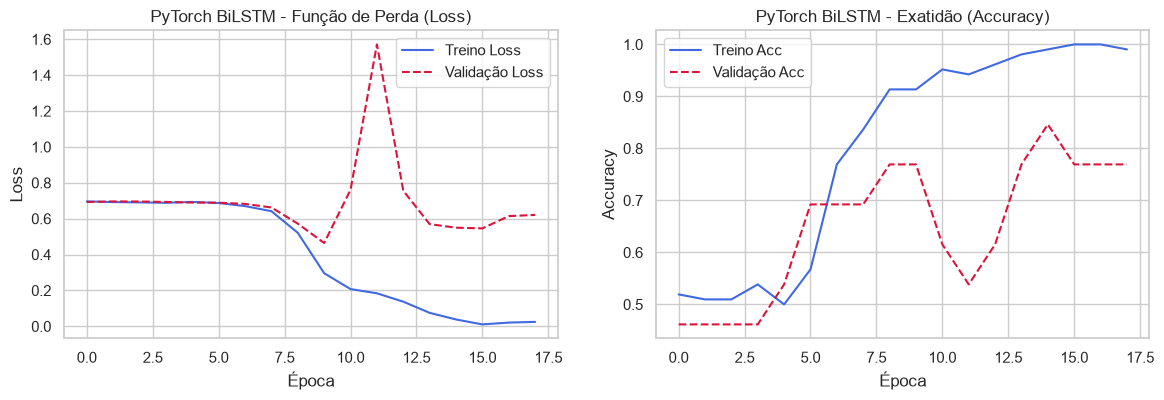

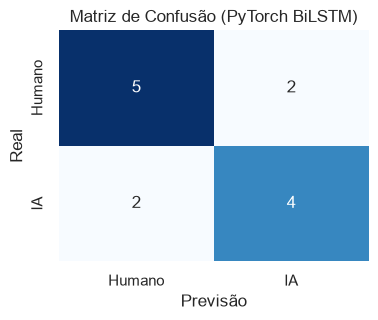

In [29]:
# 1. Tokenizador e Construção de Vocabulário
class SimpleTokenizer:
    def __init__(self, max_vocab_size=5000, max_seq_len=150):
        self.max_vocab_size = max_vocab_size
        self.max_seq_len = max_seq_len
        self.vocab = {"<PAD>": 0, "<UNK>": 1}
        
    def fit(self, texts):
        counts = Counter()
        for t in texts:
            counts.update(t.lower().strip().split())
        for token, _ in counts.most_common(self.max_vocab_size - 2):
            self.vocab[token] = len(self.vocab)
            
    def encode(self, text):
        tokens = text.lower().strip().split()
        indices = [self.vocab.get(t, self.vocab["<UNK>"]) for t in tokens]
        if len(indices) > self.max_seq_len:
            return indices[:self.max_seq_len]
        return indices + [self.vocab["<PAD>"]] * (self.max_seq_len - len(indices))

    @property
    def vocab_size(self):
        return len(self.vocab)

tokenizer = SimpleTokenizer(max_vocab_size=5000, max_seq_len=150)
tokenizer.fit(train_texts)
print(f"Vocabulário construído com {tokenizer.vocab_size} tokens únicos.")

class TextSequenceDataset(Dataset):
    def __init__(self, texts, labels, tok):
        self.X = torch.tensor([tok.encode(t) for t in texts], dtype=torch.long)
        self.y = torch.tensor(labels, dtype=torch.float32).unsqueeze(1)
    def __len__(self):
        return len(self.X)
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

train_seq_loader = DataLoader(TextSequenceDataset(train_texts, train_labels, tokenizer), batch_size=16, shuffle=True)
val_seq_loader = DataLoader(TextSequenceDataset(val_texts, val_labels, tokenizer), batch_size=16, shuffle=False)
test_seq_loader = DataLoader(TextSequenceDataset(test_texts, test_labels, tokenizer), batch_size=16, shuffle=False)

# 2. Arquitetura BiLSTM
class TextBiLSTM(nn.Module):
    def __init__(self, vocab_size, embed_dim=128, hidden_dim=64, num_layers=2, dropout_rate=0.3):
        super(TextBiLSTM, self).__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.embed_dropout = nn.Dropout(dropout_rate)
        self.lstm = nn.LSTM(
            input_size=embed_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            bidirectional=True,
            batch_first=True,
            dropout=dropout_rate if num_layers > 1 else 0.0
        )
        self.fc = nn.Sequential(
            nn.Linear(hidden_dim * 2, 64),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            nn.Linear(64, 1)
        )
        
    def forward(self, x):
        embedded = self.embed_dropout(self.embedding(x))
        lstm_out, _ = self.lstm(embedded)
        pooled, _ = torch.max(lstm_out, dim=1)
        return self.fc(pooled)

model_bilstm = TextBiLSTM(vocab_size=tokenizer.vocab_size)
opt_bilstm = optim.Adam(model_bilstm.parameters(), lr=0.002)

res_bilstm = train_and_evaluate(
    model_bilstm, train_seq_loader, val_seq_loader, test_seq_loader,
    opt_bilstm, criterion, epochs=40, patience=8,
    model_save_path="models/best_pytorch_bilstm.pt", model_name="PyTorch BiLSTM"
)

--- 
### 6. Modelo 3: Transformer Encoder com Multi-Head Self-Attention

[*] Paragem precoce na época 12! (Melhor Val Loss: 0.6319)


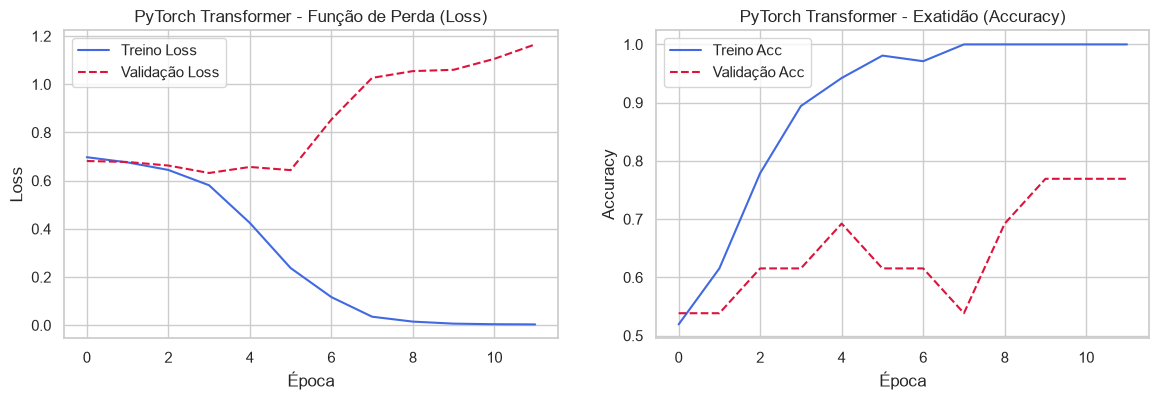

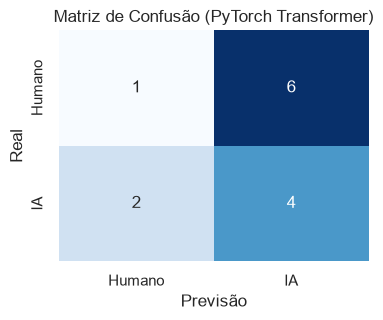

In [30]:
# 1. Codificação Posicional Sinusoidal
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=5000):
        super(PositionalEncoding, self).__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.register_buffer('pe', pe.unsqueeze(0))

    def forward(self, x):
        return x + self.pe[:, :x.size(1), :]

# 2. Arquitetura Transformer Encoder
class TextTransformer(nn.Module):
    def __init__(self, vocab_size, d_model=128, nhead=4, num_layers=2, dim_feedforward=256, dropout_rate=0.2):
        super(TextTransformer, self).__init__()
        self.embedding = nn.Embedding(vocab_size, d_model, padding_idx=0)
        self.pos_encoder = PositionalEncoding(d_model)
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead, dim_feedforward=dim_feedforward,
            dropout=dropout_rate, batch_first=True
        )
        self.transformer_encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        self.d_model = d_model
        self.classifier = nn.Sequential(
            nn.Linear(d_model, 64),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        padding_mask = (x == 0)
        out = self.embedding(x) * math.sqrt(self.d_model)
        out = self.pos_encoder(out)
        encoded = self.transformer_encoder(out, src_key_padding_mask=padding_mask)
        
        mask_expanded = (~padding_mask).unsqueeze(-1).float()
        sum_embeddings = torch.sum(encoded * mask_expanded, dim=1)
        sum_mask = mask_expanded.sum(dim=1).clamp(min=1e-9)
        pooled = sum_embeddings / sum_mask
        return self.classifier(pooled)

model_transformer = TextTransformer(vocab_size=tokenizer.vocab_size)
opt_transformer = optim.AdamW(model_transformer.parameters(), lr=0.0005, weight_decay=1e-4)

res_transformer = train_and_evaluate(
    model_transformer, train_seq_loader, val_seq_loader, test_seq_loader,
    opt_transformer, criterion, epochs=40, patience=8,
    model_save_path="models/best_pytorch_transformer.pt", model_name="PyTorch Transformer"
)

--- 
### 7. Resumo Comparativo e Análise dos Modelos

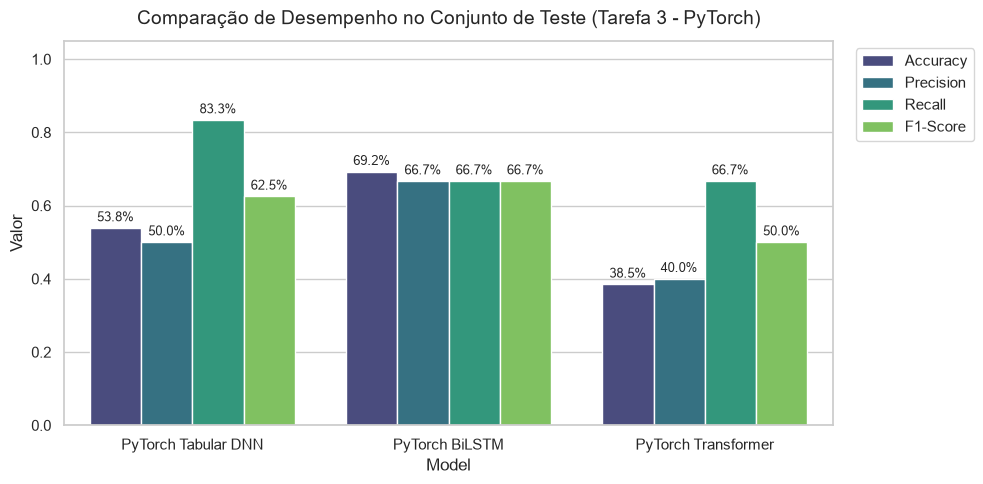

,Model,Accuracy,Precision,Recall,F1-Score,Checkpoint
0,PyTorch Tabular DNN,53.85%,50.00%,83.33%,62.50%,models/best_pytorch_dnn.pt
1,PyTorch BiLSTM,69.23%,66.67%,66.67%,66.67%,models/best_pytorch_bilstm.pt
2,PyTorch Transformer,38.46%,40.00%,66.67%,50.00%,models/best_pytorch_transformer.pt


In [31]:
df_results = pd.DataFrame([res_dnn, res_bilstm, res_transformer])

# Gráfico comparativo de barras
df_plot = df_results.melt(id_vars=['Model'], value_vars=['Accuracy', 'Precision', 'Recall', 'F1-Score'],
                          var_name='Métrica', value_name='Valor')

plt.figure(figsize=(10, 5))
ax = sns.barplot(data=df_plot, x='Model', y='Valor', hue='Métrica', palette='viridis')
plt.title('Comparação de Desempenho no Conjunto de Teste (Tarefa 3 - PyTorch)', fontsize=14, pad=12)
plt.ylim(0, 1.05)
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f'{height*100:.1f}%',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom', fontsize=9, xytext=(0, 3),
                    textcoords='offset points')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

# Tabela formatada
df_display = df_results.copy()
for col in ['Accuracy', 'Precision', 'Recall', 'F1-Score']:
    df_display[col] = df_display[col].apply(lambda x: f"{x*100:.2f}%")

display(df_display[['Model', 'Accuracy', 'Precision', 'Recall', 'F1-Score', 'Checkpoint']])

--- 
### 8. Demonstração Interativa de Inferência (Classificação em Tempo Real)

In [32]:
def classificar_texto(texto, modelo, tokenizador):
    modelo.eval()
    with torch.no_grad():
        indices = torch.tensor([tokenizador.encode(texto)], dtype=torch.long).to(device)
        prob = torch.sigmoid(modelo(indices)).item()
        pred_class = "IA (1)" if prob >= 0.5 else "Humano (0)"
        return pred_class, prob

# Exemplo com o melhor modelo (BiLSTM)
model_bilstm.load_state_dict(torch.load("models/best_pytorch_bilstm.pt", map_location=device))

exemplos = [
    "In this paper, we conduct an experimental analysis on quantum mechanics and particle physics.",
    "As an AI language model, I am designed to assist users with coding, writing, and answering questions."
]

for exp in exemplos:
    classe, prob = classificar_texto(exp, model_bilstm, tokenizer)
    print(f"Texto: '{exp}'")
    print(f"-> Classificação: {classe} | Probabilidade de IA: {prob*100:.2f}%\n")

Texto: 'In this paper, we conduct an experimental analysis on quantum mechanics and particle physics.'
-> Classificação: Humano (0) | Probabilidade de IA: 48.70%

Texto: 'As an AI language model, I am designed to assist users with coding, writing, and answering questions.'
-> Classificação: IA (1) | Probabilidade de IA: 86.12%

